# Figura 5.1 - Evolución del tuning de XGBoost

Genera una figura compacta para mostrar cómo evolucionó el AMS medio en CV durante el ajuste incremental de XGBoost sobre `P04`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raiz del proyecto.")


project_root = find_project_root()
img_dir = project_root / "img"
img_dir.mkdir(parents=True, exist_ok=True)
output_path = img_dir / "fig_5_1_evolucion_tuning_xgboost.png"

In [3]:
tuning_results = pd.DataFrame(
    [
        {
            "etapa": "Base\nP04+XGB",
            "ams_mean": 1.620982,
            "nota": "punto de partida",
        },
        {
            "etapa": "LR/estim.\n0.03, 800",
            "ams_mean": 1.631725,
            "nota": "más árboles, menor tasa",
        },
        {
            "etapa": "Reg. sin pesos\nα=0.1, λ=1",
            "ams_mean": 1.635711,
            "nota": "mejora leve",
        },
        {
            "etapa": "sample_weight\nα=0.5, λ=1",
            "ams_mean": 1.663999,
            "nota": "salto principal",
        },
        {
            "etapa": "SW04 final\nα=0.5, λ=2",
            "ams_mean": 1.670944,
            "nota": "mejor CV",
        },
    ]
)
tuning_results

,etapa,ams_mean,nota
0,Base\nP04+XGB,1.620982,punto de partida
1,"LR/estim.\n0.03, 800",1.631725,"más árboles, menor tasa"
2,"Reg. sin pesos\nα=0.1, λ=1",1.635711,mejora leve
3,"sample_weight\nα=0.5, λ=1",1.663999,salto principal
4,"SW04 final\nα=0.5, λ=2",1.670944,mejor CV


PosixPath('/home/santig14/fing/taa/1_TallerAA/img/fig_5_1_evolucion_tuning_xgboost.png')

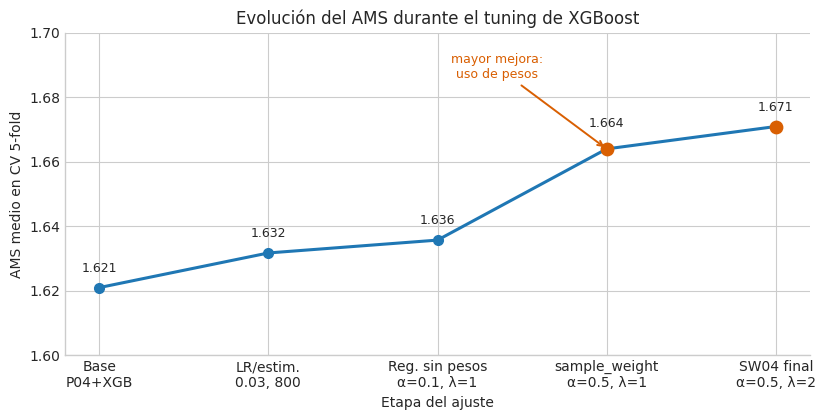

In [4]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8.4, 4.3))

line_color = "#1f77b4"
highlight_color = "#d95f02"
x = range(len(tuning_results))

ax.plot(
    x,
    tuning_results["ams_mean"],
    marker="o",
    markersize=7,
    linewidth=2.2,
    color=line_color,
)
ax.scatter([3, 4], tuning_results.loc[[3, 4], "ams_mean"], s=80, color=highlight_color, zorder=5)

for idx, row in tuning_results.iterrows():
    offset = 0.004 if idx != 3 else 0.006
    ax.text(
        idx,
        row["ams_mean"] + offset,
        f"{row['ams_mean']:.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.annotate(
    "mayor mejora:\nuso de pesos",
    xy=(3, tuning_results.loc[3, "ams_mean"]),
    xytext=(2.35, 1.686),
    arrowprops={"arrowstyle": "->", "color": highlight_color, "lw": 1.4},
    color=highlight_color,
    fontsize=9,
    ha="center",
)

ax.set_xticks(list(x))
ax.set_xticklabels(tuning_results["etapa"])
ax.set_ylabel("AMS medio en CV 5-fold")
ax.set_xlabel("Etapa del ajuste")
ax.set_title("Evolución del AMS durante el tuning de XGBoost")
ax.set_ylim(1.60, 1.70)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(output_path, dpi=220, bbox_inches="tight")
output_path